Using cache found in /home/administrateur/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /home/administrateur/.cache/torch/hub/rwightman_gen-efficientnet-pytorch_master


Loading weights:  None


Using cache found in /home/administrateur/.cache/torch/hub/intel-isl_MiDaS_master


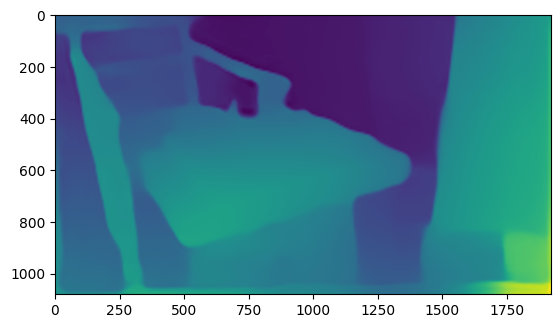

In [2]:
import torch
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

def get_MiDas_monodepth(filepath, model="small"):
    if model == "small":
        model_type = "MiDaS_small"  # MiDaS v2.1 - Small   (lowest accuracy, highest inference speed)
    else:
        model_type = "DPT_Hybrid"  # MiDaS v3 - Hybrid    (medium accuracy, medium inference speed)

    midas = torch.hub.load("intel-isl/MiDaS", model_type)
    device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
    midas.to(device)
    midas.eval()

    midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")

    if model_type == "DPT_Large" or model_type == "DPT_Hybrid":
        transform = midas_transforms.dpt_transform
    else:
        transform = midas_transforms.small_transform

    img_midas = cv2.imread(filepath)
    img_midas = cv2.cvtColor(img_midas, cv2.COLOR_BGR2RGB)

    input_batch = transform(img_midas).to(device)

    with torch.no_grad():
        prediction = midas(input_batch)

        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=img_midas.shape[:2],
            mode="bicubic",
            align_corners=False,
        ).squeeze()

    output = prediction.cpu().numpy()

    plt.imshow(output)
    plt.show()


get_MiDas_monodepth("right.png")